# Motion Vector Demonstration

## Frame extraction from GIF

In [1]:
import numpy as np
import cv2
import scipy
from PIL import Image, ImageSequence

# Google Colab's OpenCV image display function
from google.colab.patches import cv2_imshow

# to upload images on Colab
from google.colab import files
uploaded = files.upload()

In [2]:
def extract_frames(gif_path):
  with Image.open(gif_path) as im:
    frames = [np.array(frame.convert('RGB')) for frame in ImageSequence.Iterator(im)]
  return frames

In [3]:
test_frames = extract_frames('running.gif')
print(np.array(test_frames).shape)

# Just for convenience to have nice and even numbers
test_frames_resized = [cv2.resize(frame, (224, 160), interpolation=cv2.INTER_LINEAR) for frame in test_frames]
print(np.array(test_frames_resized).shape)

(8, 165, 220, 3)
(8, 160, 224, 3)


In [4]:
frames_YCrCb = np.array([cv2.cvtColor(frame, cv2.COLOR_RGB2YCR_CB) for frame in test_frames_resized])
frames_Y = frames_YCrCb[:,:,:,0]
frames_Cr = frames_YCrCb[:,:,:,1]
frames_Cb = frames_YCrCb[:,:,:,2]

print(frames_Y.shape)
print(frames_Cb.shape)
print(frames_Cr.shape)

(8, 160, 224)
(8, 160, 224)
(8, 160, 224)


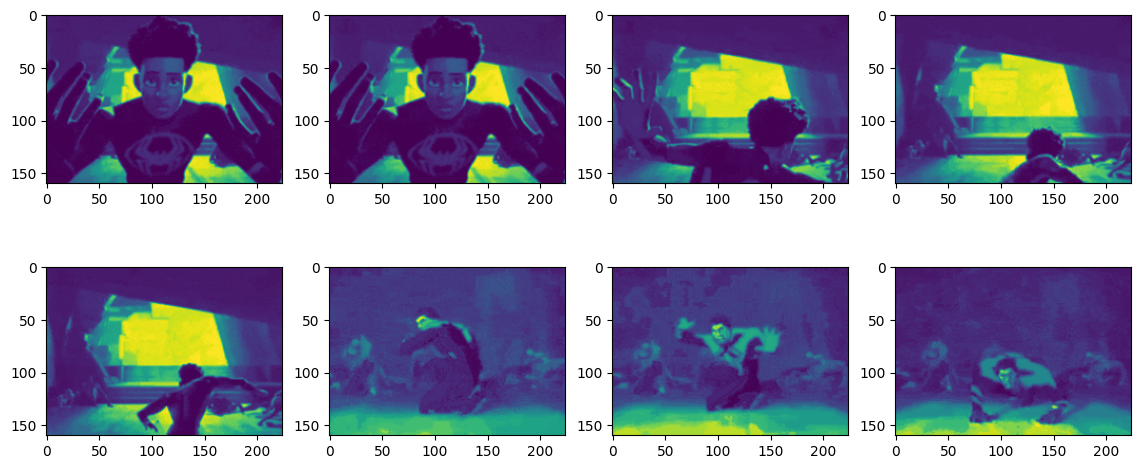

In [6]:
import matplotlib.pyplot as plt
fig = plt.figure(figsize=(14, 6))

plt.subplot(241)
plt.imshow(frames_Y[0])
plt.subplot(242)
plt.imshow(frames_Y[1])
plt.subplot(243)
plt.imshow(frames_Y[2])
plt.subplot(244)
plt.imshow(frames_Y[3])
plt.subplot(245)
plt.imshow(frames_Y[4])
plt.subplot(246)
plt.imshow(frames_Y[5])
plt.subplot(247)
plt.imshow(frames_Y[6])
plt.subplot(248)
plt.imshow(frames_Y[7])

## Encode motion vectors

In [7]:
pip install patchify

In [20]:
from patchify import patchify

def frame_encoding(frames):
  intra_frame = frames[0,:,:]
  predicted_frames_recon = []
  predicted_frames_diff = []
  for i in range(1,len(frames)):
    curr_frame = frames[i]
    prev_frame = frames[i-1]
    MB_curr = patchify(curr_frame, (16, 16), step=16)
    MB_prev = patchify(prev_frame, (16, 16), step=16)

    r, c, _, _ = MB_curr.shape
    vectors = np.zeros((r, c, 2))
    for j in range(r):
      for k in range(c):
        diff = np.ones((17, 17)) * 1e9
        m_start, m_end, n_start, n_end = -8, 8, -8, 8
        if j == 0: m_start = 0
        if j == r - 1: m_end = 0
        if k == 0: n_start = 0
        if k == c - 1: n_end = 0

        for m in range(m_start, m_end):
          for n in range(n_start, n_end):
            delta = MB_curr[j, k, :, :] - prev_frame[int((j*16)+m):int(((j+1)*16)+m),int((k*16)+n):int(((k+1)*16)+n)]
            diff[m+8,n+8] = abs(sum(sum(delta)))

        flat_idx = np.argmin(diff)
        x, y = np.unravel_index(flat_idx, diff.shape)
        vectors[j,k,:] = [x-8, y-8]

    MB_recon = np.zeros((r, c, 16, 16))

    for j in range(r):
      for k in range(c):
        v = vectors[j,k,:]
        MB_recon[j,k,:,:] = prev_frame[int((j*16)+v[0]):int(((j+1)*16)+v[0]),int((k*16)+v[1]):int(((k+1)*16)+v[1])]

    MB_diff = MB_curr - MB_recon

    predicted_frames_recon.append(MB_recon)
    predicted_frames_diff.append(MB_diff)
  return patchify(intra_frame, (16, 16), step=16), predicted_frames_recon, predicted_frames_diff


In [24]:
I_blocks, P_blocks, P_diff_blocks = frame_encoding(frames_Y)

print(I_blocks.shape)
print(np.array(P_blocks).shape)
print(np.array(P_diff_blocks).shape)

(10, 14, 16, 16)
(7, 10, 14, 16, 16)
(7, 10, 14, 16, 16)


## Decoding

In [32]:
from patchify import unpatchify
I_recon = unpatchify(I_blocks, (160, 224))

P_recon = [unpatchify(P_block, (160, 224)) for P_block in P_blocks]
P_diff = [unpatchify(P_block, (160, 224)) for P_block in P_diff_blocks]

Text(0.5, 1.0, 'Estimated P Frame 7')

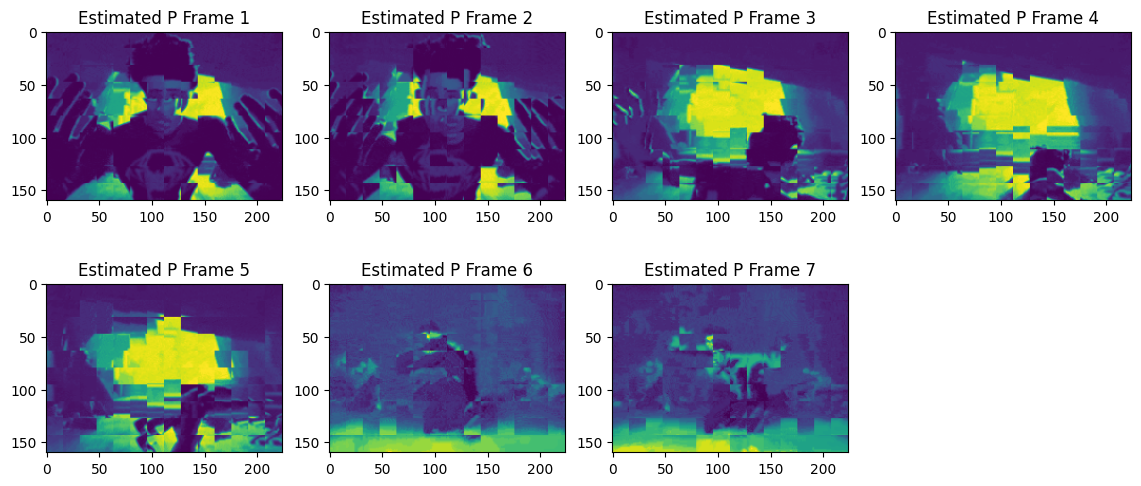

In [61]:
import matplotlib.pyplot as plt
fig = plt.figure(figsize=(14, 6))

plt.subplot(241)
plt.imshow(P_recon[0])
plt.title("Estimated P Frame 1")
plt.subplot(242)
plt.imshow(P_recon[1])
plt.title("Estimated P Frame 2")
plt.subplot(243)
plt.imshow(P_recon[2])
plt.title("Estimated P Frame 3")
plt.subplot(244)
plt.imshow(P_recon[3])
plt.title("Estimated P Frame 4")
plt.subplot(245)
plt.imshow(P_recon[4])
plt.title("Estimated P Frame 5")
plt.subplot(246)
plt.imshow(P_recon[5])
plt.title("Estimated P Frame 6")
plt.subplot(247)
plt.imshow(P_recon[6])
plt.title("Estimated P Frame 7")

Text(0.5, 1.0, 'P Frame Difference 7')

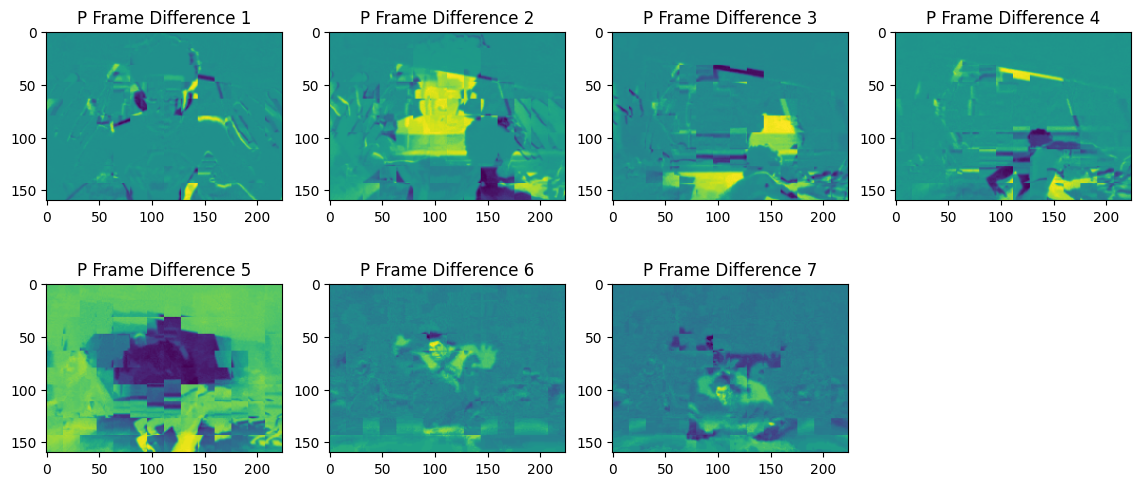

In [62]:
fig = plt.figure(figsize=(14, 6))

plt.subplot(241)
plt.imshow(P_diff[0])
plt.title("P Frame Difference 1")
plt.subplot(242)
plt.imshow(P_diff[1])
plt.title("P Frame Difference 2")
plt.subplot(243)
plt.imshow(P_diff[2])
plt.title("P Frame Difference 3")
plt.subplot(244)
plt.imshow(P_diff[3])
plt.title("P Frame Difference 4")
plt.subplot(245)
plt.imshow(P_diff[4])
plt.title("P Frame Difference 5")
plt.subplot(246)
plt.imshow(P_diff[5])
plt.title("P Frame Difference 6")
plt.subplot(247)
plt.imshow(P_diff[6])
plt.title("P Frame Difference 7")

In [46]:
P_full_recon = np.array(P_recon).astype(float) + np.array(P_diff)
P_full_recon = P_full_recon.astype(int)

Text(0.5, 1.0, 'Reconstructed P Frame 7')

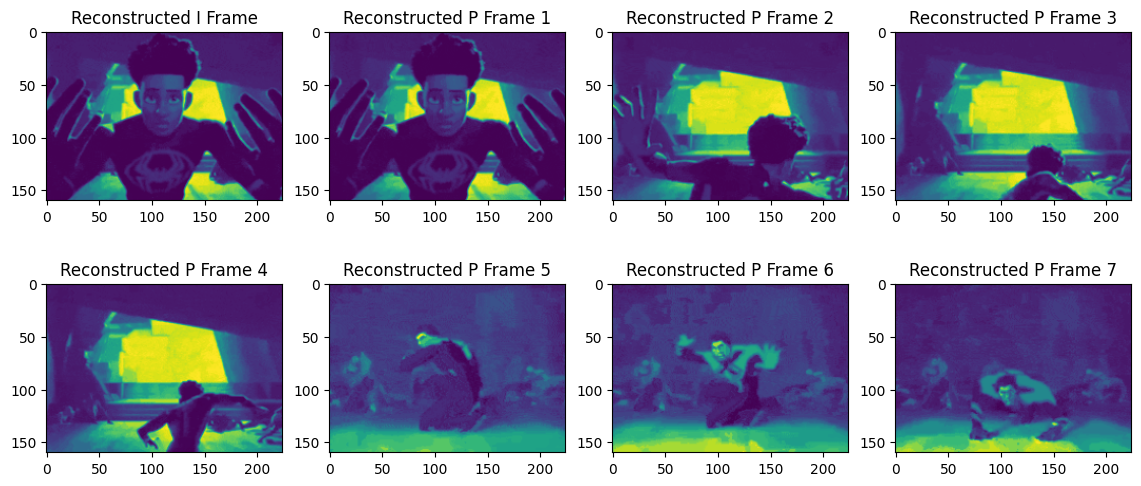

In [63]:
fig = plt.figure(figsize=(14, 6))

plt.subplot(241)
plt.imshow(I_recon)
plt.title("Reconstructed I Frame")
plt.subplot(242)
plt.imshow(P_full_recon[0])
plt.title("Reconstructed P Frame 1")
plt.subplot(243)
plt.imshow(P_full_recon[1])
plt.title("Reconstructed P Frame 2")
plt.subplot(244)
plt.imshow(P_full_recon[2])
plt.title("Reconstructed P Frame 3")
plt.subplot(245)
plt.imshow(P_full_recon[3])
plt.title("Reconstructed P Frame 4")
plt.subplot(246)
plt.imshow(P_full_recon[4])
plt.title("Reconstructed P Frame 5")
plt.subplot(247)
plt.imshow(P_full_recon[5])
plt.title("Reconstructed P Frame 6")
plt.subplot(248)
plt.imshow(P_full_recon[6])
plt.title("Reconstructed P Frame 7")

## Reconstruct the frames

In [58]:
frames_recon = []
frames_recon.append(cv2.cvtColor(cv2.merge((I_recon, frames_Cr[0], frames_Cb[0])), cv2.COLOR_YCrCb2RGB))

for i in range(len(P_full_recon)):
  P_frame_Y = P_full_recon[i].astype(np.uint8)
  frames_recon.append(cv2.cvtColor(cv2.merge((P_frame_Y, frames_Cr[i+1], frames_Cb[i+1])), cv2.COLOR_YCrCb2RGB))

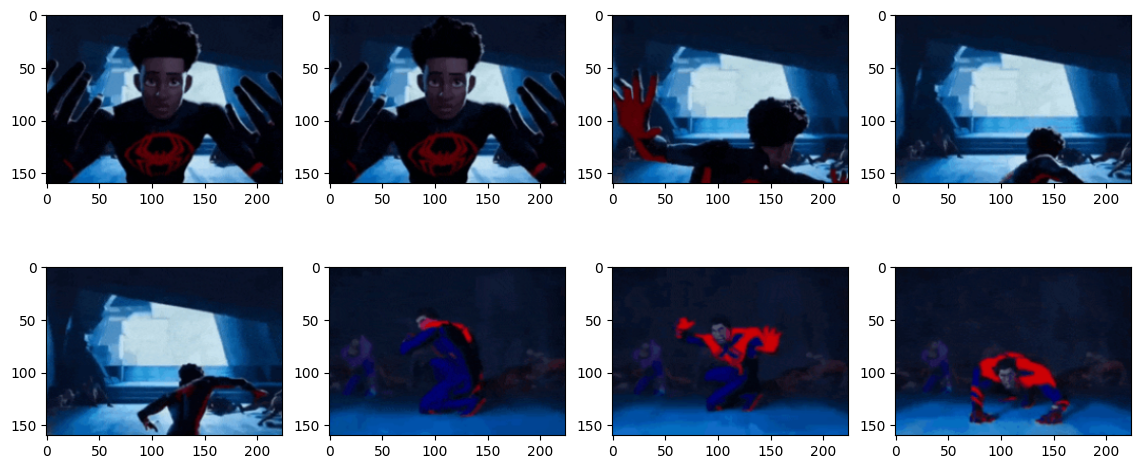

In [59]:
fig = plt.figure(figsize=(14, 6))

plt.subplot(241)
plt.imshow(frames_recon[0])
plt.subplot(242)
plt.imshow(frames_recon[1])
plt.subplot(243)
plt.imshow(frames_recon[2])
plt.subplot(244)
plt.imshow(frames_recon[3])
plt.subplot(245)
plt.imshow(frames_recon[4])
plt.subplot(246)
plt.imshow(frames_recon[5])
plt.subplot(247)
plt.imshow(frames_recon[6])
plt.subplot(248)
plt.imshow(frames_recon[7])